# Prerequisite 06B · 卷积网络与序列模型速成

[上一章：PyTorch](Prerequisite06_PyTorch.ipynb) · [预备篇导航](Prerequisite00_Index.ipynb) · [下一章：Gymnasium](Prerequisite07_Gymnasium.ipynb)

**为什么需要这一课：**本仓库有 12 章的代码用 `nn.Conv2d` 处理图像或棋盘类观测（第 3、6、8、9、11、12、14、16、18、19、20、22 章），
第 13–14 章用 `nn.Embedding` 和 `nn.LSTM` 处理文本。原书默认你学过这些。

本课不追求把 CNN/RNN 学透，只解决“读懂原书网络结构、不被 shape 卡住”：

1. 卷积在算什么、输出尺寸怎么算；
2. Atari 观测怎样预处理（灰度、缩放、帧堆叠、通道顺序、归一化）；
3. 训练一个能在 CPU 上几秒跑完的小 CNN；
4. 文本序列：token → embedding → LSTM 的 shape 流。

建议时长：4–6 小时。先学第 1–4 节即可开始 Chapter06；第 5 节在 Chapter13 前回来看。


## 1. 卷积：用小窗口在图上“滑动找图案”

全连接层把每个像素都连到每个神经元，84×84×4 的输入有 28224 个数，参数会爆炸，而且忽略了“相邻像素相关”。
卷积层用一个小 kernel（比如 3×3）在图上滑动，每个位置做“窗口 × kernel 求和”：

- 同一个 kernel 在所有位置共用参数 → 参数少；
- 一个 kernel 检测一种局部图案（边缘、球、挡板）；
- 多个 kernel → 多个输出通道（feature map）。

下面用一个“竖直边缘检测” kernel 处理一张小图。


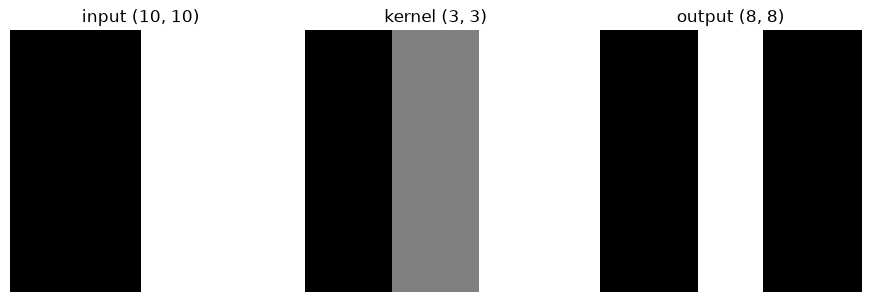

输出只在边缘附近非零： [0. 0. 0. 3. 3. 0. 0. 0.]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

image = np.zeros((10, 10)); image[:, 5:] = 1.0              # 左黑右白
kernel = np.array([[-1., 0., 1.], [-1., 0., 1.], [-1., 0., 1.]])  # 检测“从左到右变亮”

out = F.conv2d(torch.tensor(image)[None, None], torch.tensor(kernel)[None, None])[0, 0].numpy()
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (title, data) in zip(axes, [("input", image), ("kernel", kernel), ("output", out)]):
    ax.imshow(data, cmap="gray"); ax.set_title(f"{title} {data.shape}"); ax.axis("off")
plt.tight_layout(); plt.show(); plt.close()
print("输出只在边缘附近非零：", out[0])


## 2. 输出尺寸与 shape 流

$$\text{out}=\left\lfloor\frac{\text{in}+2p-k}{s}\right\rfloor+1$$

PyTorch 的图像张量约定为 **`(B, C, H, W)`**：batch、通道、高、宽。下面是原书 DQN 使用的经典结构，
逐层打印 shape——读任何新网络时都建议这样做一次。


In [2]:
conv = nn.Sequential(
    nn.Conv2d(4, 32, kernel_size=8, stride=4), nn.ReLU(),
    nn.Conv2d(32, 64, kernel_size=4, stride=2), nn.ReLU(),
    nn.Conv2d(64, 64, kernel_size=3, stride=1), nn.ReLU(),
)
x = torch.zeros(1, 4, 84, 84)
print("input   ", tuple(x.shape))
for layer in conv:
    x = layer(x)
    if isinstance(layer, nn.Conv2d):
        print(f"{layer.__class__.__name__:8s}", tuple(x.shape))
print("flatten ", x.numel(), "→ 接 Linear(3136, 512) → Linear(512, n_actions)")
n_params = sum(p.numel() for p in conv.parameters())
print("卷积部分参数量:", n_params, "（若用全连接层连接 28224 维输入到 512 维，需要约", 28224 * 512, "个参数）")


input    (1, 4, 84, 84)
Conv2d   (1, 32, 20, 20)
Conv2d   (1, 64, 9, 9)
Conv2d   (1, 64, 7, 7)
flatten  3136 → 接 Linear(3136, 512) → Linear(512, n_actions)
卷积部分参数量: 77984 （若用全连接层连接 28224 维输入到 512 维，需要约 14450688 个参数）


## 3. Atari 观测预处理：每一步都有理由

| 步骤 | 做法 | 理由 |
|---|---|---|
| 灰度 | RGB → 单通道 | 颜色对多数游戏不重要，数据量减为 1/3 |
| 缩放 | 210×160 → 84×84 | 计算量大幅下降 |
| 跳帧 | 同一动作重复 4 帧 | 相邻帧几乎一样，节省计算 |
| 帧堆叠 | 最近 4 帧叠成 `(4,84,84)` | 单帧看不出速度和方向（马尔可夫性） |
| 通道前置 | `(H,W,C)` → `(C,H,W)` | PyTorch 卷积的约定 |
| 归一化 | `uint8 / 255.0` | 输入落在 0–1，训练更稳定；replay buffer 里仍存 uint8 省内存 |

这些都写在 Chapter06 的 `lib/wrappers.py` 里。下面演示“为什么要帧堆叠”：一帧只能看到球在哪，两帧相减才看得出往哪走。


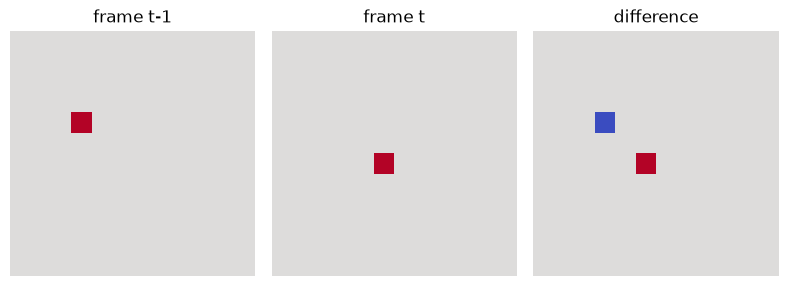

只看 frame t 无法判断球的速度；堆叠后网络可以自己学出“差分”。


In [3]:
def ball_frame(x, y, size=12):
    frame = np.zeros((size, size)); frame[y, x] = 1.0
    return frame

f1, f2 = ball_frame(3, 4), ball_frame(5, 6)
fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
for ax, (title, data) in zip(axes, [("frame t-1", f1), ("frame t", f2), ("difference", f2 - f1)]):
    ax.imshow(data, cmap="coolwarm", vmin=-1, vmax=1); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show(); plt.close()
print("只看 frame t 无法判断球的速度；堆叠后网络可以自己学出“差分”。")


## 4. 训练一个小 CNN（CPU 几秒）

任务：12×12 的带噪图像里有一条横线或竖线，判断方向。流程与 Prerequisite06 的训练循环完全相同，
只是模型换成卷积网络。训练完成后准确率应接近 100%。


In [4]:
torch.manual_seed(0)
rng = np.random.default_rng(0)

def make_bars(n, size=12):
    images = rng.normal(0, 0.3, size=(n, 1, size, size)).astype(np.float32)
    labels = rng.integers(0, 2, size=n)
    for i, label in enumerate(labels):
        pos = rng.integers(2, size - 2)
        if label == 0:
            images[i, 0, pos, :] += 1.0   # 横线
        else:
            images[i, 0, :, pos] += 1.0   # 竖线
    return torch.tensor(images), torch.tensor(labels)

x_train, y_train = make_bars(512)
x_val, y_val = make_bars(256)

model = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3), nn.ReLU(),      # (B,1,12,12) → (B,8,10,10)
    nn.MaxPool2d(2),                                 # → (B,8,5,5)
    nn.Flatten(),                                    # → (B,200)
    nn.Linear(8 * 5 * 5, 2),                         # → (B,2) 两类 logits
)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
for epoch in range(30):
    logits = model(x_train)
    loss = F.cross_entropy(logits, y_train)
    optimizer.zero_grad(); loss.backward(); optimizer.step()

model.eval()
with torch.no_grad():
    val_acc = (model(x_val).argmax(dim=1) == y_val).float().mean().item()
print("训练 loss:", round(loss.item(), 4), " 验证准确率:", round(val_acc, 3))
assert val_acc > 0.9


训练 loss: 0.0491  验证准确率: 1.0


## 5. 序列模型：为 Chapter13/14 准备的最小知识

文本先被切成 token，再变成整数 id。之后的 shape 流是：

| 步骤 | 模块 | shape |
|---|---|---|
| token id | （输入） | `(B, T)` 整数 |
| 词向量 | `nn.Embedding(vocab, E)` | `(B, T, E)` |
| 序列编码 | `nn.LSTM(E, H, batch_first=True)` | 输出 `(B, T, H)`；最后隐状态 `h_n` 为 `(1, B, H)` |
| 汇总 | 取 `h_n[-1]` | `(B, H)` → 可以接 Q 值头或策略头 |

要点：`batch_first=True` 时 batch 在第 0 维（否则默认时间在第 0 维，是常见 bug）；不同长度的句子需要 padding 到同一长度。
Chapter13 后半部分还会用预训练的 Transformer 句向量和 LLM 接口，那时再补 [注意力机制](https://zh.d2l.ai/chapter_attention-mechanisms/index.html) 即可。


In [5]:
vocab_size, embed_dim, hidden_dim = 50, 16, 32
tokens = torch.tensor([[3, 7, 9, 0, 0],      # 一句长度 3，后面用 0 padding
                       [5, 2, 8, 4, 1]])     # 一句长度 5
embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)

emb = embedding(tokens)
outputs, (h_n, c_n) = lstm(emb)
sentence_vec = h_n[-1]
print("tokens    ", tuple(tokens.shape))
print("embedding ", tuple(emb.shape))
print("LSTM out  ", tuple(outputs.shape), " h_n", tuple(h_n.shape))
print("句子向量  ", tuple(sentence_vec.shape), "→ 可接 nn.Linear(32, n_actions)")


tokens     (2, 5)
embedding  (2, 5, 16)
LSTM out   (2, 5, 32)  h_n (1, 2, 32)
句子向量   (2, 32) → 可接 nn.Linear(32, n_actions)


## 6. 常见误区

- **通道顺序搞错：**Gymnasium/OpenCV 常给 `(H,W,C)`，PyTorch 要 `(C,H,W)`；不报错但学不到东西时，先查这个。
- **忘了归一化：**`uint8` 直接送进网络，数值大且 dtype 不对。
- **手写 flatten 尺寸：**换环境或改分辨率就崩；用假输入跑一次自动计算。
- **在 CPU 上训练 Atari：**Pong 在 CPU 上可能要很多小时，先在 CartPole/小网格上把流程调通，再上 GPU 或租用云 GPU。


## 自动批改练习

每道题先读题、再写代码、最后运行同一格。看到 `[通过]` 才算完成；`[未通过]` 会说明哪里不对。
参考答案默认折叠，建议独立尝试至少 10 分钟后再看。


In [6]:
# 自动检查工具：每道练习末尾都会调用 check(test_xxx)。
# 未完成或有错时只打印提示，不会中断 Run All。
def check(test):
    try:
        test()
    except NotImplementedError:
        print(f"[未完成] {test.__name__}：把 raise NotImplementedError 换成你的代码，再运行本格。")
    except AssertionError as error:
        print(f"[未通过] {test.__name__}：{error}")
    except Exception as error:  # 代码本身报错，也给出可读提示
        print(f"[代码报错] {test.__name__}：{type(error).__name__}: {error}")
    else:
        print(f"[通过] {test.__name__}")


### 练习 1：卷积输出尺寸公式

实现 `conv_out(size, kernel, stride=1, padding=0)`，返回
$\left\lfloor \frac{size+2\cdot padding-kernel}{stride} \right\rfloor + 1$。
然后用它验证 DQN 经典结构：84 → (k=8,s=4) → 20 → (k=4,s=2) → 9 → (k=3,s=1) → 7。


In [7]:
def conv_out(size, kernel, stride=1, padding=0):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_conv_out():
    assert conv_out(84, 8, 4) == 20, "84 经过 k=8,s=4 应得 20"
    assert conv_out(20, 4, 2) == 9, "20 经过 k=4,s=2 应得 9"
    assert conv_out(9, 3, 1) == 7, "9 经过 k=3,s=1 应得 7"
    assert conv_out(32, 3, 1, padding=1) == 32, "k=3,p=1,s=1 应保持尺寸不变"

check(test_conv_out)


[未完成] test_conv_out：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
def conv_out(size, kernel, stride=1, padding=0):
    return (size + 2 * padding - kernel) // stride + 1
```

</details>


### 练习 2：手写二维卷积（单通道）

实现 `conv2d_single(image, kernel)`：`image` 为 `(H,W)`，`kernel` 为 `(k,k)`，stride=1、无 padding，
输出 `(H-k+1, W-k+1)`。每个输出位置 = 对应窗口与 kernel **逐元素相乘再求和**。
测试会和 PyTorch 的 `F.conv2d` 对比（PyTorch 的“卷积”实际是互相关，不翻转 kernel，和这里一致）。

<details><summary>提示（卡住 10 分钟再看）</summary>

两层循环遍历输出的行 i、列 j：`out[i, j] = np.sum(image[i:i+k, j:j+k] * kernel)`。

</details>


In [8]:
import numpy as np

def conv2d_single(image, kernel):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np
import torch
import torch.nn.functional as F

def test_conv2d_single():
    rng = np.random.default_rng(0)
    image = rng.normal(size=(6, 7)); kernel = rng.normal(size=(3, 3))
    out = conv2d_single(image, kernel)
    assert out.shape == (4, 5), f"(6,7) 经 3x3 卷积应得 (4,5)，得到 {out.shape}"
    ref = F.conv2d(torch.tensor(image)[None, None], torch.tensor(kernel)[None, None])[0, 0].numpy()
    assert np.allclose(out, ref), "结果应与 torch.nn.functional.conv2d 一致"

check(test_conv2d_single)


[未完成] test_conv2d_single：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def conv2d_single(image, kernel):
    H, W = image.shape
    k = kernel.shape[0]
    out = np.zeros((H - k + 1, W - k + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(image[i:i + k, j:j + k] * kernel)
    return out
```

</details>


### 练习 3：帧堆叠 FrameStack

单帧画面看不出球往哪飞，所以 Atari DQN 把最近 4 帧叠在一起作为状态。实现类 `FrameStack(k)`：
- `reset(frame)`：用同一帧填满 k 个位置，返回 `(k,H,W)`；
- `step(frame)`：丢掉最旧一帧、加入新帧，返回 `(k,H,W)`，**最新帧在最后**。

<details><summary>提示（卡住 10 分钟再看）</summary>

用 `collections.deque(maxlen=k)`，返回 `np.stack(list(self.frames), axis=0)`。

</details>


In [9]:
import numpy as np
from collections import deque

class FrameStack:
    def __init__(self, k):
        self.k = k

    def reset(self, frame):
        raise NotImplementedError

    def step(self, frame):
        raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_frame_stack():
    fs = FrameStack(4)
    first = fs.reset(np.zeros((2, 3)))
    assert first.shape == (4, 2, 3), f"应为 (4,2,3)，得到 {first.shape}"
    for value in (1, 2, 3, 4, 5):
        state = fs.step(np.full((2, 3), value))
    assert state.shape == (4, 2, 3)
    assert [int(state[i, 0, 0]) for i in range(4)] == [2, 3, 4, 5], "应只保留最近 4 帧，且最新帧在最后"

check(test_frame_stack)


[未完成] test_frame_stack：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np
from collections import deque

class FrameStack:
    def __init__(self, k):
        self.k = k
        self.frames = deque(maxlen=k)

    def reset(self, frame):
        self.frames.clear()
        for _ in range(self.k):
            self.frames.append(frame)
        return np.stack(list(self.frames), axis=0)

    def step(self, frame):
        self.frames.append(frame)
        return np.stack(list(self.frames), axis=0)
```

</details>


### 练习 4：图像观测转成网络输入

环境返回的一批观测是 `uint8`、shape `(B,H,W,C)`（通道在最后，取值 0–255）。
PyTorch 卷积需要 `float32`、`(B,C,H,W)`、取值约 0–1。实现 `to_network_input(obs)`，返回 `torch.Tensor`。

<details><summary>提示（卡住 10 分钟再看）</summary>

`torch.as_tensor(obs).permute(0, 3, 1, 2).float() / 255.0`。

</details>


In [10]:
import numpy as np
import torch

def to_network_input(obs):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np
import torch

def test_to_network_input():
    obs = np.zeros((2, 84, 84, 4), dtype=np.uint8); obs[1, 10, 20, 3] = 255
    x = to_network_input(obs)
    assert isinstance(x, torch.Tensor), "应返回 torch.Tensor"
    assert tuple(x.shape) == (2, 4, 84, 84), f"应为 (B,C,H,W)=(2,4,84,84)，得到 {tuple(x.shape)}"
    assert x.dtype == torch.float32, f"dtype 应为 float32，得到 {x.dtype}"
    assert abs(x[1, 3, 10, 20].item() - 1.0) < 1e-6 and x.max() <= 1.0, "应除以 255 归一化，且通道维移动正确"

check(test_to_network_input)


[未完成] test_to_network_input：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np
import torch

def to_network_input(obs):
    return torch.as_tensor(obs).permute(0, 3, 1, 2).float() / 255.0
```

</details>


### 练习 5：自动计算 flatten 尺寸

把卷积部分接到全连接层时，需要知道展平后的长度。手算容易错，原书代码的做法是**用一个全 0 的假输入跑一次**。
实现 `flat_size(conv, input_shape)`：`input_shape` 形如 `(C,H,W)`，返回 `conv` 输出展平后的整数长度。

<details><summary>提示（卡住 10 分钟再看）</summary>

`with torch.no_grad(): out = conv(torch.zeros(1, *input_shape))`，返回 `int(out.numel())`。

</details>


In [11]:
import torch
import torch.nn as nn

def flat_size(conv, input_shape):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import torch.nn as nn

def test_flat_size():
    conv = nn.Sequential(
        nn.Conv2d(4, 32, 8, stride=4), nn.ReLU(),
        nn.Conv2d(32, 64, 4, stride=2), nn.ReLU(),
        nn.Conv2d(64, 64, 3, stride=1), nn.ReLU(),
    )
    assert flat_size(conv, (4, 84, 84)) == 64 * 7 * 7, "经典 DQN 卷积输出应为 64*7*7=3136"
    assert flat_size(conv, (4, 100, 100)) == 64 * 9 * 9, "换输入尺寸后应自动得到 64*9*9"

check(test_flat_size)


[未完成] test_flat_size：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import torch
import torch.nn as nn

def flat_size(conv, input_shape):
    with torch.no_grad():
        out = conv(torch.zeros(1, *input_shape))
    return int(out.numel())
```

</details>


## 过关标准

- [ ] 5 道练习全部 `[通过]`；
- [ ] 不看代码，能写出 DQN 卷积部分每层输出 shape：`(4,84,84) → (32,20,20) → (64,9,9) → (64,7,7) → 3136`；
- [ ] 能解释帧堆叠、通道前置和 `/255` 各自的理由；
- [ ] 能说出 `(B,T) → (B,T,E) → (B,H)` 每一步由哪个模块完成。

**选读：**[动手学深度学习 · 卷积神经网络](https://zh.d2l.ai/chapter_convolutional-neural-networks/index.html)；
[动手学深度学习 · 循环神经网络](https://zh.d2l.ai/chapter_recurrent-neural-networks/index.html)（Chapter13 前再看）。
